Need to check the range of rotation rates we can have with spherical symmetry of gravity being valid.

From Vallis 2017:
$$\vec{g} \equiv \vec{g_\text{eff}} = \vec{g_\text{grav}} + \Omega^2 \vec{r_\perp}$$

So centripetal will be maximised at the equator. I am unsure where radially it will occur as $\vec{g_\text{grav}}$ decreases radially but centripetal increases. As such I will just check the whole profile.
As I am using a non-rotating case to check this the overall averaged radial profile (struc) can be used.

To calculate gravity I will use:
$$g=\frac{Gm(r)}{r^2}$$

Now it is hard to access the value of $m(r)$ from the dumps, so as the density roughly matches MESA ic, I can use that to calculate it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import glob
import pandas as pd
import os

In [2]:
r_sun = 6.9570000000000000E+010
r_tot = 5.7671763407229273 * r_sun
# r_bot = 0.4 * r_tot
# r_top = 0.9 * r_tot
# Nr = 570
# Ntheta = 360
# Nphi = 720
# dr_grid = (r_top - r_bot) / Nr
r_env_init = 0.2836686568328816 * r_tot
m_sun = 1.9884098706980504E+033

In [3]:
all_files = sorted(glob.glob('ic_analysis/profile1.data'))
all_files

['ic_analysis/profile1.data']

In [4]:
# MESA_headers = 
with open(all_files[0], "r") as f:
    f.readline()
    f.readline()
    f.readline()
    f.readline()
    f.readline()
    MESA_headers = f.readline().split()
MESA_headers

['zone',
 'mass',
 'logR',
 'logT',
 'logRho',
 'logP',
 'x_mass_fraction_H',
 'y_mass_fraction_He',
 'z_mass_fraction_metals',
 'logdq',
 'dq_ratio',
 'q',
 'radius',
 'velocity',
 'v_div_r',
 'pressure_scale_height',
 'mmid',
 'logxq',
 'dr',
 'temperature',
 'entropy',
 'pressure',
 'logPgas',
 'pgas_div_ptotal',
 'eta',
 'mu',
 'grada',
 'free_e',
 'csound',
 'v_div_csound',
 'eps_grav',
 'eps_nuc',
 'non_nuc_neu',
 'pp',
 'cno',
 'tri_alpha',
 'c_alpha',
 'n_alpha',
 'o_alpha',
 'ne_alpha',
 'na_alpha',
 'mg_alpha',
 'si_alpha',
 's_alpha',
 'ar_alpha',
 'ca_alpha',
 'ti_alpha',
 'cr_alpha',
 'fe_co_ni',
 'c12_c12',
 'c12_o16',
 'o16_o16',
 'pnhe4',
 'photo',
 'ni56_co56',
 'co56_fe56',
 'other',
 'abar',
 'ye',
 'h1',
 'he3',
 'he4',
 'c12',
 'n14',
 'o16',
 'ne20',
 'mg24',
 'log_opacity',
 'luminosity',
 'logL',
 'total_energy',
 'mlt_mixing_length',
 'mlt_mixing_type',
 'log_conv_vel',
 'gradT',
 'gradr',
 'grad_temperature',
 'grad_density',
 'gradL',
 'sch_stable',
 'ledoux_

In [5]:
mesa_df = pd.DataFrame(np.genfromtxt(all_files[0],skip_header=6),columns=MESA_headers)
mesa_df.set_index('zone')

,mass,logR,logT,logRho,logP,x_mass_fraction_H,y_mass_fraction_He,z_mass_fraction_metals,logdq,dq_ratio,...,am_log_D_SH,am_log_D_SSI,am_log_D_ES,am_log_D_GSF,am_log_D_ST,am_log_nu_ST,dynamo_log_B_r,dynamo_log_B_phi,brunt_N2,brunt_B
zone,,,,,,,,,,,,,,,,,,,,,
1.0,2.000000e+01,0.760963,4.540705,-8.994687,3.914323,0.700000,0.280000,0.020000,-12.698970,1.000000,...,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,1.084063e-05,0.000000e+00
2.0,2.000000e+01,0.760959,4.541396,-8.989985,3.918589,0.700000,0.280000,0.020000,-12.522879,0.666667,...,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,1.072829e-05,0.000000e+00
3.0,2.000000e+01,0.760953,4.542111,-8.985200,3.922963,0.700000,0.280000,0.020000,-12.662040,1.377721,...,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,1.039462e-05,0.000000e+00
4.0,2.000000e+01,0.760948,4.542711,-8.981240,3.926608,0.700000,0.280000,0.020000,-12.662040,1.000000,...,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,1.015686e-05,0.000000e+00
5.0,2.000000e+01,0.760944,4.543312,-8.977338,3.930224,0.700000,0.280000,0.020000,-12.662040,1.000000,...,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,9.922954e-06,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4662.0,6.250523e-06,-1.910127,7.553384,0.675444,16.430078,0.698646,0.280791,0.020562,-6.806144,2.000000,...,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-2.586113e-16,1.826107e-09
4663.0,3.125262e-06,-2.010473,7.553387,0.675452,16.430090,0.698646,0.280791,0.020562,-7.107174,2.000000,...,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-1.629735e-16,1.630580e-09
4664.0,1.562631e-06,-2.110817,7.553389,0.675457,16.430097,0.698646,0.280791,0.020562,-7.408204,2.000000,...,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-99.0,-1.039009e-16,-6.327222e-09


In [6]:
G = 6.67430e-8

In [7]:
Omega_Sun = 2.702e-6
Omega = np.linspace(0, 35, 36) * Omega_Sun
# centrifugal = Omega ** 2 * r # r = r_perp for equator

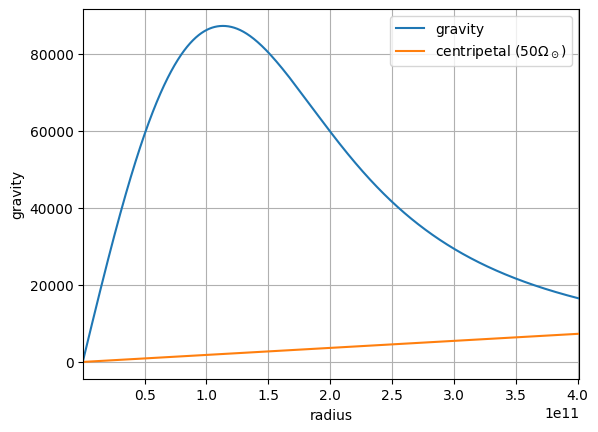

In [10]:
r = r_sun * 10 ** mesa_df['logR']
gravity = G * m_sun * mesa_df['mass'] / (r ** 2)
plt.plot(r, gravity, label="gravity")
plt.plot(r, ((50 * Omega_Sun) ** 2) * r, label=r"centripetal ($50\Omega_\odot$)")
plt.xlabel('radius')
plt.ylabel('gravity')
plt.grid()
plt.xlim(np.min(r), np.max(r))
plt.legend()
plt.savefig("gravity_profile.png", bbox_inches="tight")

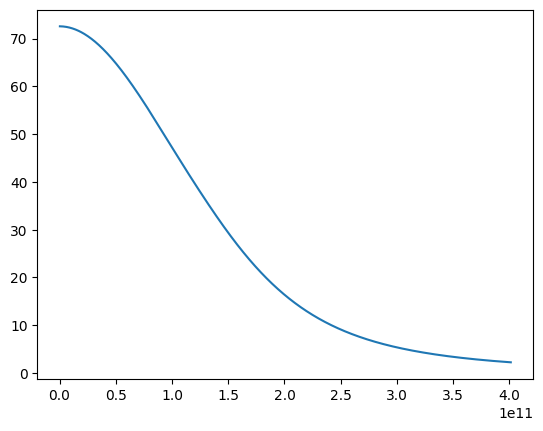

In [11]:
centrifugal = ((50 * Omega_Sun) ** 2) * r
plt.plot(r, gravity / centrifugal)

OK! So this shows me that actually as gravity decreases towards the surface, that means the maximum will be as r increases!

So currently I am unsure what is the important region for me, and as such I will calculate for two points:
1. r=R*
2. r=r_out (of simulation)

In [12]:
def plot_Omega_dependence(radius):
    r_idx = np.argmin(abs(radius - r))
    centrifugal = (Omega ** 2) * radius
    plt.plot(Omega / Omega_Sun, centrifugal / gravity[r_idx])
    plt.xlabel('Omega [sun]')
    plt.ylabel('centrifugal / gravity')
    plt.xlim(np.min(Omega / Omega_Sun), np.max(Omega / Omega_Sun))
    plt.grid()
    plt.title(f'eval at {radius / r[0]:.4f} R*')

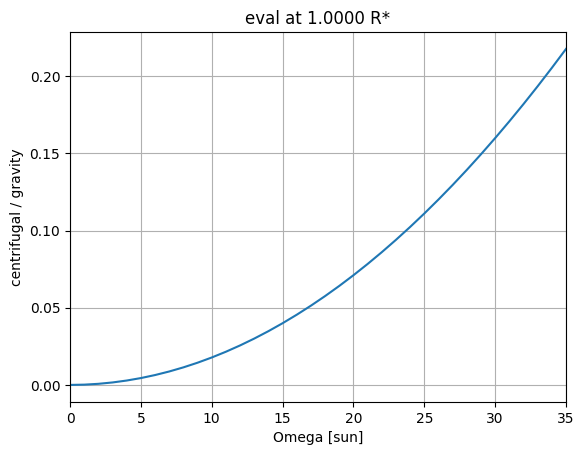

In [13]:
plot_Omega_dependence(r[0])

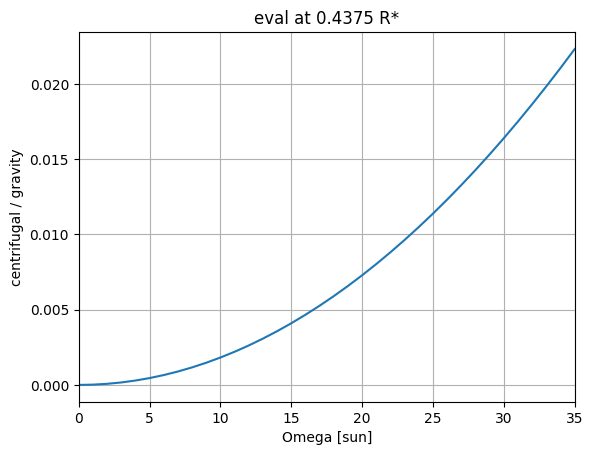

In [14]:
plot_Omega_dependence(0.4375 * r[0])
plt.savefig("gravity_ratio.png")